# Task 2 — Intrinsic evaluation: perplexity

Perplexity measures how well a model predicts held-out text it never saw in training:

PP = exp( −(1/M) Σ_j log P(w_j | h_j) )

where the sum runs over the M held-out tokens w_j (every word plus each sentence's `</s>`), and h_j
is the n−1 tokens before w_j in the same sentence. It is the inverse geometric mean of the
probabilities the model assigned. Lower is better; PP = 50 means the model was, on average, as
uncertain as a uniform choice among 50 words.

The dev split is used for decisions (none are tuned here except checking consistency); test numbers
are the reported result.

In [1]:
# --- Setup ---------------------------------------------------------------------------
# On Colab / Kaggle, first get this repository and the corpus:
#   !git clone <your-repo-url> nlp-assignment-1
#   %cd nlp-assignment-1
#   !pip install -q wordcloud gdown
#   !gdown 1jEOAORylTBAiNKes_JerD6gFF7cnLFyr -O data/   # GPAC, from the assignment's Drive link
import os, sys
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
DATA = os.path.join(ROOT, "data")
CORPUS = os.path.join(DATA, "GPAC.txt")     # a .txt file, a directory of .txt files, or a .zip
MODEL_DIR = os.path.join(DATA, "gpac")      # preprocessed splits, vocabulary and counts go here
FIGURES = os.path.join(ROOT, "figures"); os.makedirs(FIGURES, exist_ok=True)
MAX_CHARS = None                            # e.g. 50_000_000 to use only part of the corpus

import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 80)

In [2]:
from ngram import pipeline
from ngram.evaluate import perplexity_table
vocab, counts, ids, stats = pipeline.load(MODEL_DIR)
res = pd.concat([pd.DataFrame(perplexity_table(counts, ids[s])).assign(split=s) for s in ("dev", "test")])
display(res.pivot_table(index=["split", "model"], columns="n", values="perplexity", sort=False).round(1))
display(res.pivot_table(index=["split", "model"], columns="n", values="zero_prob_tokens", sort=False))
print(f"OOV rate (test tokens mapped to <unk>): {res.oov_rate.iloc[0]:.2%}")

n                    1        2         3         4
split model                                        
dev   mle      11443.4      inf       inf       inf
      laplace  11483.1  43116.8  311939.8  488054.6
      kn       11443.4    815.3     512.0     491.5
test  mle      11420.6      inf       inf       inf
      laplace  11460.3  43053.4  311683.5  488202.3
      kn       11420.6    814.2     510.5     489.8

n                1         2          3          4
split model                                       
dev   mle      0.0  651875.0  2546827.0  3074413.0
      laplace  0.0       0.0        0.0        0.0
      kn       0.0       0.0        0.0        0.0
test  mle      0.0  648640.0  2532247.0  3058670.0
      laplace  0.0       0.0        0.0        0.0
      kn       0.0       0.0        0.0        0.0

OOV rate (test tokens mapped to <unk>): 1.97%


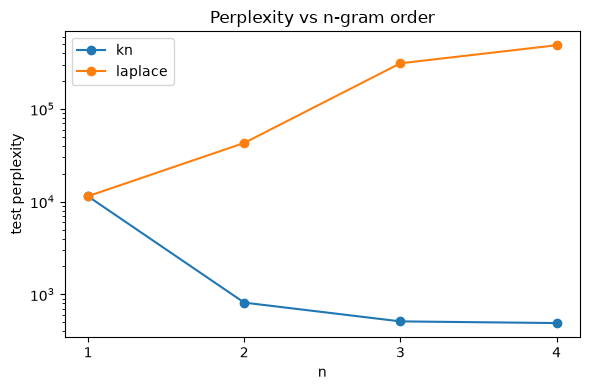

In [3]:
test = res[(res.split == "test") & (res.model != "mle")]
fig, ax = plt.subplots(figsize=(6, 4))
for kind, g in test.groupby("model"):
    ax.plot(g.n, g.perplexity, marker="o", label=kind)
ax.set(xlabel="n", ylabel="test perplexity", xticks=[1, 2, 3, 4], yscale="log",
       title="Perplexity vs n-gram order")
ax.legend(); plt.tight_layout(); plt.savefig(f"{FIGURES}/perplexity.png", dpi=150)

### Kneser-Ney discounts

Kneser-Ney subtracts a fixed discount D_k from every order-k count and gives the freed mass to the
lower-order distribution. D_k = n1 / (n1 + 2·n2), where n1 and n2 are the numbers of order-k
n-grams with count exactly 1 and exactly 2. "raw" is the highest order of a model (occurrence
counts; n1 and n2 are counted before pruning); "adj" are lower orders (continuation counts: the
number of distinct words preceding the n-gram).

In [4]:
from ngram.models import count_stats
st_ = count_stats(counts)
pd.DataFrame({kind: {k: st_.discount(kind, k) for k in range(1, 5 if kind == "raw" else 4)}
              for kind in ("raw", "adj")}).rename_axis("order")

,raw,adj
order,,
1,0.000000,0.366393
2,0.548371,0.803166
3,0.609320,0.685686
4,0.637598,NaN


### Effect of training-set size

Each model is retrained on the first 10 %, 25 % and 50 % of the training sentences (same vocabulary,
same pruning) and scored on the test split with Kneser-Ney; 100 % is the main model. Each rebuild
takes a few minutes.

In [5]:
import tempfile
from ngram.counts import NGramCounts
from ngram.models import KneserNeyModel
from ngram.vocab import BOS
train = ids["train"]
n_sent = stats["split_sentences"]["train"]
counts._stats = None   # release the cached Kneser-Ney aggregates of the full model while rebuilding
curve = []
for frac in (0.1, 0.25, 0.5, 1.0):
    if frac == 1.0:
        sub = counts
    else:
        # position of the first <s> after frac of the sentences
        cut = int(np.searchsorted(np.cumsum(np.asarray(train) == BOS), int(n_sent * frac) + 1))
        with tempfile.TemporaryDirectory(dir=MODEL_DIR) as work:
            sub = NGramCounts.build(train[:cut], len(vocab), 4, counts.meta["min_counts"], workdir=work)
    for n in range(1, 5):
        curve.append({"train fraction": frac, "n": n,
                      "perplexity": KneserNeyModel(sub, n).perplexity(ids["test"])[0]})
    del sub
pd.DataFrame(curve).pivot(index="train fraction", columns="n", values="perplexity").round(1)

n,1,2,3,4
train fraction,,,,
0.10,13514.7,3529.0,3309.5,4271.1
0.25,12547.9,2275.3,2030.7,2765.0
0.50,11799.1,1297.5,978.7,1106.8
1.00,11420.6,814.2,510.5,489.8


### Effect of pruning

On the smaller training sets the 4-gram model scores *worse* than the 3-gram model, which
interpolated Kneser-Ney should not do. The cause is pruning. When a 3-word history h was seen
but all its continuations occurred once and were pruned, the 4-gram level keeps none of h's
mass, so P(w | h) falls back entirely to the trigram level. In a 4-gram model that level uses
continuation counts N1+(• g), which estimate how many different contexts a word follows. That
distribution is meant only for words the higher order did not predict, and it predicts held-out
text worse than the raw trigram counts that the 3-gram model uses directly. With little data
almost every 4-gram is a singleton, so this fallback dominates.

The cell below rebuilds the 10 % model with and without pruning.

In [6]:
n_sent = stats["split_sentences"]["train"]
cut = int(np.searchsorted(np.cumsum(np.asarray(train) == BOS), int(n_sent * 0.1) + 1))
prune_rows = []
for mins in ([1, 1, 1, 1], counts.meta["min_counts"]):
    with tempfile.TemporaryDirectory(dir=MODEL_DIR) as work:
        sub = NGramCounts.build(train[:cut], len(vocab), 4, mins, workdir=work)
    prune_rows.append({"3-/4-grams seen once": "kept" if mins[-1] == 1 else "pruned",
                       **{n: KneserNeyModel(sub, n).perplexity(ids["test"])[0] for n in range(1, 5)}})
    del sub
pd.DataFrame(prune_rows).set_index("3-/4-grams seen once").round(1)

,1,2,3,4
3-/4-grams seen once,,,,
kept,13514.7,3529.0,2911.1,2808.5
pruned,13514.7,3529.0,3309.5,4271.1


### Discussion

- **MLE** assigns probability zero to every test n-gram unseen in training, so its perplexity is
  infinite for n ≥ 2. The zero-probability table shows how many test tokens hit this: about 16 %
  of tokens for bigrams, 62 % for trigrams and 75 % for 4-grams. Its unigram perplexity is finite only
  because `<unk>` absorbs unseen words.
- **Laplace** adds 1 to each of the V ≈ 1,000,000 possible continuations of every history. A
  history seen c(h •) times keeps only c(h •) / (c(h •) + V) of its probability for the words
  actually observed, so longer histories, which are seen fewer times, give almost all their mass
  to unseen words. Perplexity therefore *rises* with n, from about 11 000 to about 490 000.
- **Kneser-Ney** falls from about 11 400 (unigram) to 814 (bigram), 511 (trigram) and 490
  (4-gram). The largest gain is the first word of context. Each further word helps less, because
  most test 3- and 4-grams were never seen and the model relies on lower orders for them.
- **Why the absolute numbers are high.** Amharic attaches prepositions, articles, possessives and
  conjunctions to the word (በአፍሪካ = "in Africa", የቡና = "of coffee"). The vocabulary therefore
  reaches 1.9 M distinct words, so each position has far more possible words than in English. English
  n-gram perplexities of about 100–200 are not comparable.
- **More data** lowers perplexity at every order; the 4-gram model gains the most because its
  counts are the sparsest.
- **Pruning** trades accuracy for memory. Without it the 4-gram tables would not fit in this
  machine's RAM; with it, higher orders gain less than they could, and on small data they lose.
- Perplexities are comparable only between models sharing the same vocabulary and test set.